# 04 — VR2 Intermediate-mass summary: DATA and MC (4mu)

Compare **PP · DP · PD** from left to right in a 1×3 layout of the **Mu isolation × |Δφ|** plane.
The mass selection is **150≤Mjj<300 GeV**, and both channels use the common fixed WP **(mu iso, |Δφ|)=(0.30, 2.6)**.
**Partner isolation is fixed to 0≤iso<0.5 in every VR and in the nominal SR.**

Following notebooks 13–16 in `ABCD_plane_summary`, this notebook summarizes DATA and MC distributions,
observed A and the ABCD prediction, κ and its uncertainty, 1D/2D scans, background composition and effective counts,
and **S/B in each ABCD region for 120 signal hypotheses**.
The displayed scan ranges are **iso 0–2 and Δφ 0–π**, using **11×14=154 points** at stored native bin boundaries.
As in notebooks 13–16, zero boundaries are excluded from the calculation because they produce degenerate quadrants; the axes still start at zero.
The iso=2 and Δφ=π boundaries are included. Undefined closure and low-statistics states remain visible.
The nominal MC SR is shown separately as a reference.

Run with `Restart → Run All`. The notebook uses the shared calculation and plotting helpers and the original coffea inputs.
It does not load previous candidate JSON files or saved plateaus.

In [1]:
from pathlib import Path
import sys

SIDM_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if p.name == "sidm"), None)
if SIDM_DIR is None:
    raise RuntimeError("Run this notebook from inside the sidm repository.")
if str(SIDM_DIR.parent) not in sys.path:
    sys.path.insert(0, str(SIDM_DIR.parent))
NOTEBOOK_DIR = SIDM_DIR / "studies" / "ABCD_finalize"
INPUT_DIR = SIDM_DIR / "studies" / "ABCD_plane_summary"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

# Import coffea/pyarrow before defining NumPy 2 pickle compatibility aliases.
import coffea.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
if int(np.__version__.split(".")[0]) < 2:
    import numpy.core as _numpy_core
    import numpy.core.multiarray as _numpy_multiarray
    import numpy.core.numeric as _numpy_numeric
    sys.modules.setdefault("numpy._core", _numpy_core)
    sys.modules.setdefault("numpy._core.multiarray", _numpy_multiarray)
    sys.modules.setdefault("numpy._core.numeric", _numpy_numeric)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "pdf.fonttype": 42,
                     "figure.max_open_warning": 0})
pd.set_option("display.max_columns", 20)

for helper in ("abcd_finalize_common.py", "abcd_finalize_plots.py"):
    if not (NOTEBOOK_DIR / helper).is_file():
        raise FileNotFoundError(f"Required shared helper: {NOTEBOOK_DIR / helper}")
from abcd_finalize_common import run_candidate_comparison, export_candidate_comparison
from abcd_finalize_plots import make_comparison_figures


## 1. VR definitions and common boundaries

| Category | LJ0 / LJ1 displacement | Mass | Partner isolation |
|---|---|---|---|
| PP | P / P | $150\leq M_{jj}<300$ GeV | 0≤iso<0.5 |
| DP | D / P | $150\leq M_{jj}<300$ GeV | 0≤iso<0.5 |
| PD | P / D | $150\leq M_{jj}<300$ GeV | 0≤iso<0.5 |

LJ0 and LJ1 are the leading and subleading mu-LJs in pT. For each mu-LJ, P means max pixel hits>2 and D means ≤2. The LJs are not reordered after selection.

**DD is excluded from this VR and is not projected from DATA.** Each of PP, DP and PD contains at least one P requirement, separating these categories from the nominal DD SR.
Inclusive displacement selections such as `P/any`, `any/P` and `any/any` are not used.
The two channels share the mass selection, partner isolation, fixed WP and scan coordinates.

The plane uses LJ0 isolation; partner isolation refers to LJ1. No additional Δφ event precut is applied.
The nominal SR is **DD, Mjj≥150 GeV, 0≤partner iso<0.5** and is shown using **MC only**.

The ABCD regions are A=low iso/high Δφ, B=high iso/high Δφ, C=low iso/low Δφ and D=high iso/low Δφ.
Values exactly on a boundary belong to the high side. Mass intervals include the lower bound and exclude the upper bound.

In [2]:
TOPOLOGY = '4mu'
VR = 'VR2'
NOTEBOOK_NAME = '04_MuIso_DPhi_4mu_VR2_summary.ipynb'
OUTPUT_DIR = NOTEBOOK_DIR / '04_4mu_VR2_summary_outputs'
CONFIG = {
    'topology': TOPOLOGY, 'vr': VR, 'candidate_order': ['PP', 'DP', 'PD'],
    'output_dir': OUTPUT_DIR,
    'notebook_path': NOTEBOOK_DIR / NOTEBOOK_NAME,
    'sr_reference_dir': INPUT_DIR / '12_Optimized_ABCD_4mu_comparison_outputs',
    'bkg_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_bkg_merged_samples_v1',
    'signal_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_signal_merged_samples_v1',
    'data_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_data_merged_samples_v1',
    'current_hist': 'abcd6d_' + TOPOLOGY,
    'expected_current_channel': 'abcd6d_inclusive_' + TOPOLOGY + '_dxySpread_cosAlpha_mu_veto_eHEM',
    'mass_min': 150.0, 'mass_max': 300.0,
    'partner_iso_low': 0., 'partner_iso_high': .5,
    'tx': .3, 'ty': 2.6,
    'scan_mu_iso': [.05, .1, .15, .2, .25, .3, .4, .5, .75, 1., 2.],
    'scan_abs_dphi': [.5, 1., 1.5, 2., 2.2, 2.4, 2.6, 2.7, 2.8, 2.9, 3., 3.05, 3.1, np.pi],
    'closure_band': (.9, 1.1), 'min_neff': 10., 'purity_limit': .10,
}
print('Channel:', TOPOLOGY, '| VR:', VR, '| Categories:', CONFIG['candidate_order'], '| Output:', OUTPUT_DIR)


Channel: 4mu | VR: VR2 | Categories: ['PP', 'DP', 'PD'] | Output: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_finalize/04_4mu_VR2_summary_outputs


## 2. Signal contamination, statistics and validation

- As in notebooks 13–16, evaluate **60 2Mu2E + 60 4Mu hypotheses** with masses of 200–1000 GeV individually in each analysis channel. Distinct signal hypotheses are not summed. The 100/150 GeV hypotheses are outside this diagnostic range.
- At each WP, require **$S/B_{MC}<0.10$** for every signal hypothesis and every ABCD region, with a positive background denominator. Low mass alone is not taken to imply small signal contamination.
- **No DD signal leakage veto is applied.** S/B uses MC central values; passing does not imply that an upper bound including the uncertainty is below 10%.
- DATA values that fail the S/B requirement remain `NaN` or blocked without stopping execution. Distributions and correlations are shown only for permitted DATA selections. Nominal DD SR DATA is not evaluated.
- Scan thresholds use only native edges of the stored histogram. No new candidates are selected and no plateau optimization is performed. Validate the selections, category exclusivity and separation from the nominal SR.
- ABCD calculations exclude isolation underflow and include isolation overflow. Both Δφ flow bins are included. Partner isolation and mass use only the specified half-open intervals.
- The ±10% κ band is a reference range. Inspect uncertainties, effective counts and zero/negative sideband states together; κ close to 1 alone does not establish VR suitability.
- The summary field `scan_closure_diagnostic_pass_points` counts points with κ∈[0.9,1.1], σκ≤0.2 and DATA count≥10 in every ABCD region. It is not used to change the fixed VR/WP or to mask DATA.
- **The purity requirement also applies to individual displayed bins in 2D DATA distributions.** After folding the isolation tail/overflow and angle flow exactly as in the plot, mask any bin whose maximum $S/B_{MC}$ over the 120 signals is $\geq0.10$. Also mask bins with zero/negative background or invalid MC support. The color scale uses only visible DATA bins.
- This bin mask applies only to the 2D distribution display. ABCD yields, closure and scans use the existing region-integrated S/B gate and are not recalculated from a plane with masked bins removed.


## 3. Recalculation from original inputs: DATA and MC summary

Evaluate signal contamination using 18 background samples and 120 signal hypotheses, then process DATA in the permitted VR selections.
Display the selections, fixed-WP closure, DATA gate decisions across the scan, MC effective counts and definition checks together.

In [3]:
results = run_candidate_comparison(CONFIG)
tables = results['tables']
with pd.option_context('display.max_columns', None):
    display(tables['selection'][['plane', 'state0', 'state1', 'partner_iso_low', 'partner_iso_high',
                                 'mass_low', 'mass_high', 'tx', 'ty']])
    display(tables['summary'])
    display(tables['closure'][['plane', 'source', 'A', 'B', 'C', 'D', 'pred', 'pred_error',
                               'kappa', 'kappa_error', 'pull', 'neff_min', 'low_stat',
                               'approved', 'status']])
    display(tables['validation'])


MC 20/138 (18 backgrounds + 120 individual signal hypotheses)


MC 40/138 (18 backgrounds + 120 individual signal hypotheses)


MC 60/138 (18 backgrounds + 120 individual signal hypotheses)


MC 80/138 (18 backgrounds + 120 individual signal hypotheses)


MC 100/138 (18 backgrounds + 120 individual signal hypotheses)


...

DATA 68/68


,plane,state0,state1,partner_iso_low,partner_iso_high,mass_low,mass_high,tx,ty
0,PP,P,P,0.0,0.5,150.0,300.0,0.3,2.6
1,DP,D,P,0.0,0.5,150.0,300.0,0.3,2.6
2,PD,P,D,0.0,0.5,150.0,300.0,0.3,2.6


,candidate,nominal_approved,DATA_kappa,DATA_kappa_error,MC_kappa,MC_kappa_error,nominal_max_S_B,scan_points,data_approved_points,scan_kappa_min,scan_kappa_max,scan_kappa_span,scan_max_S_B,scan_min_MC_neff,scan_min_DATA_count,scan_closure_diagnostic_pass_points
0,PP,True,1.117219,0.195008,18.432717,18.730225,0.010863,154,125,0.755828,14.166667,13.410838,0.239919,1.0,1.0,24
1,DP,True,0.441558,0.281365,0.067571,0.075350,0.038127,154,111,0.211538,8.228571,8.017033,0.283432,1.0,0.0,0
2,PD,True,0.823529,0.422805,9.192383,11.930574,0.012649,154,100,0.568047,2.361111,1.793064,2.695983,1.0,0.0,0


,plane,source,A,B,C,D,pred,pred_error,kappa,kappa_error,pull,neff_min,low_stat,approved,status
0,PP,MC,446.014053,243.033089,17.827699,179.061209,24.196870,22.492048,18.432717,18.730225,2.286844,2.246182,True,True,LOW_STAT_SIDEBAND
1,PP,DATA,264.000000,268.000000,82.000000,93.000000,236.301075,38.596837,1.117219,0.195008,0.661429,82.000000,False,True,OK
2,DP,MC,9.837689,14.305649,6.531205,0.641758,145.589387,139.369854,0.067571,0.075350,-0.973246,2.021604,True,True,LOW_STAT_SIDEBAND
3,DP,DATA,34.000000,28.000000,11.000000,4.000000,77.000000,47.254629,0.441558,0.281365,-0.903114,4.000000,True,True,LOW_STAT_SIDEBAND
4,PD,MC,23.567710,4.410476,9.681298,16.654430,2.563830,3.132542,9.192383,11.930574,1.948029,1.034426,True,True,LOW_STAT_SIDEBAND
5,PD,DATA,15.000000,17.000000,15.000000,14.000000,18.214286,8.082686,0.823529,0.422805,-0.358630,14.000000,False,True,OK


,plane,vr,mass_low,mass_high,states,scan_points,data_approved_points,check,passed
0,PP,VR2,150.0,300.0,PP,154,125,"VR whitelist, SR disjointness, unique scan and...",True
1,DP,VR2,150.0,300.0,DP,154,111,"VR whitelist, SR disjointness, unique scan and...",True
2,PD,VR2,150.0,300.0,PD,154,100,"VR whitelist, SR disjointness, unique scan and...",True


## 4. Comparison of 3 displacement categories in a 1×3 layout

Keep the style of notebooks 13–16: black circles for observed yields, orange squares for predictions and blue for κ.
The 1D scans show observed A and BC/D, κ, and **the maximum MC S/B across 120 signals and all ABCD regions**, from top to bottom.
The isolation scan fixes Δφ=2.6, and the Δφ scan fixes iso=0.30. The 2D maps use the same 154 scan points.

The κ=0.9 and 1.1 lines and green band mark the ±10% reference range. The S/B=10% reference line is also shown.
The S/B panel below DATA is the same MC diagnostic. The signal hypothesis and region giving the largest S/B may change with WP and are recorded in the CSV files.
DATA failing the gate is shown as blocked, while the MC results remain visible.
Isolation-tail folding is used only for the distribution display, not for closure or correlations.

In [4]:
figures = make_comparison_figures(results, CONFIG)
figure_lookup = {stem: figure for figure, stem in figures}
for figure, stem in figures:
    plt.close(figure)


### 4.1. DATA and MC closure at the fixed WP

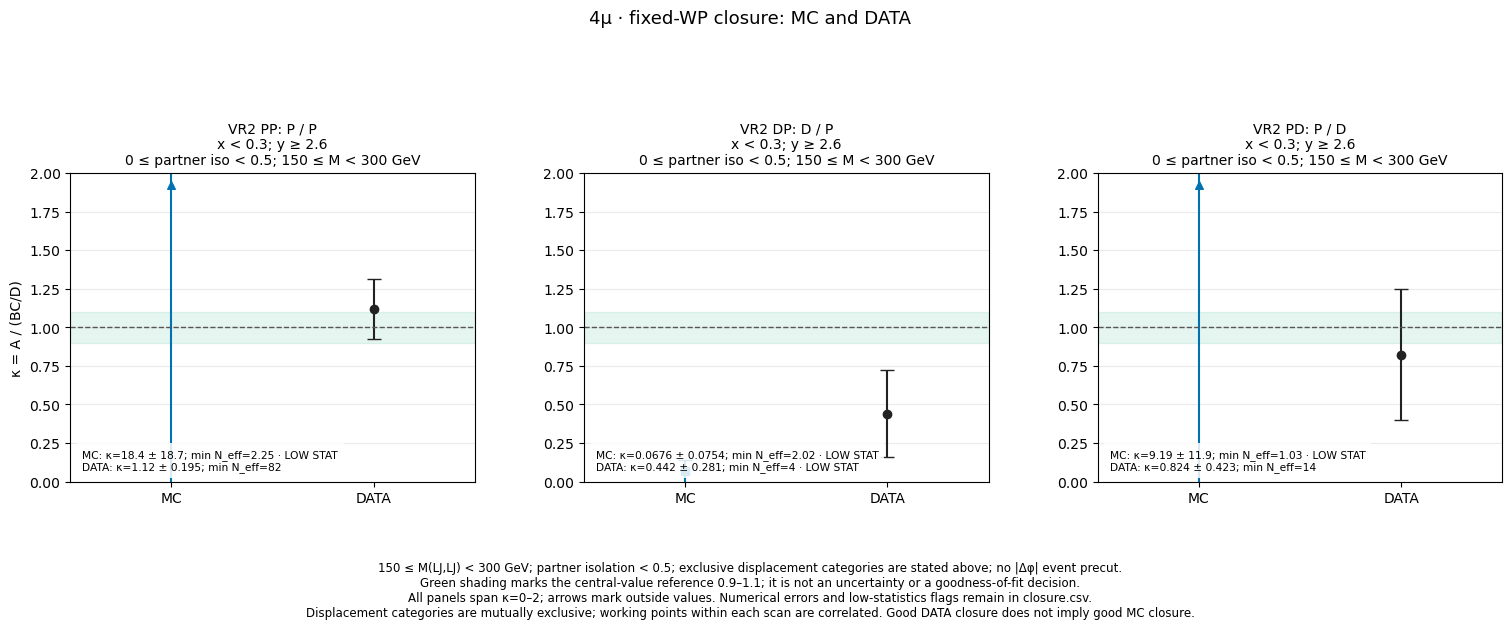

In [5]:
display(figure_lookup['combined_VR_selected_closure'])

### 4.2. Maximum S/B over all signals in each ABCD region at the fixed WP

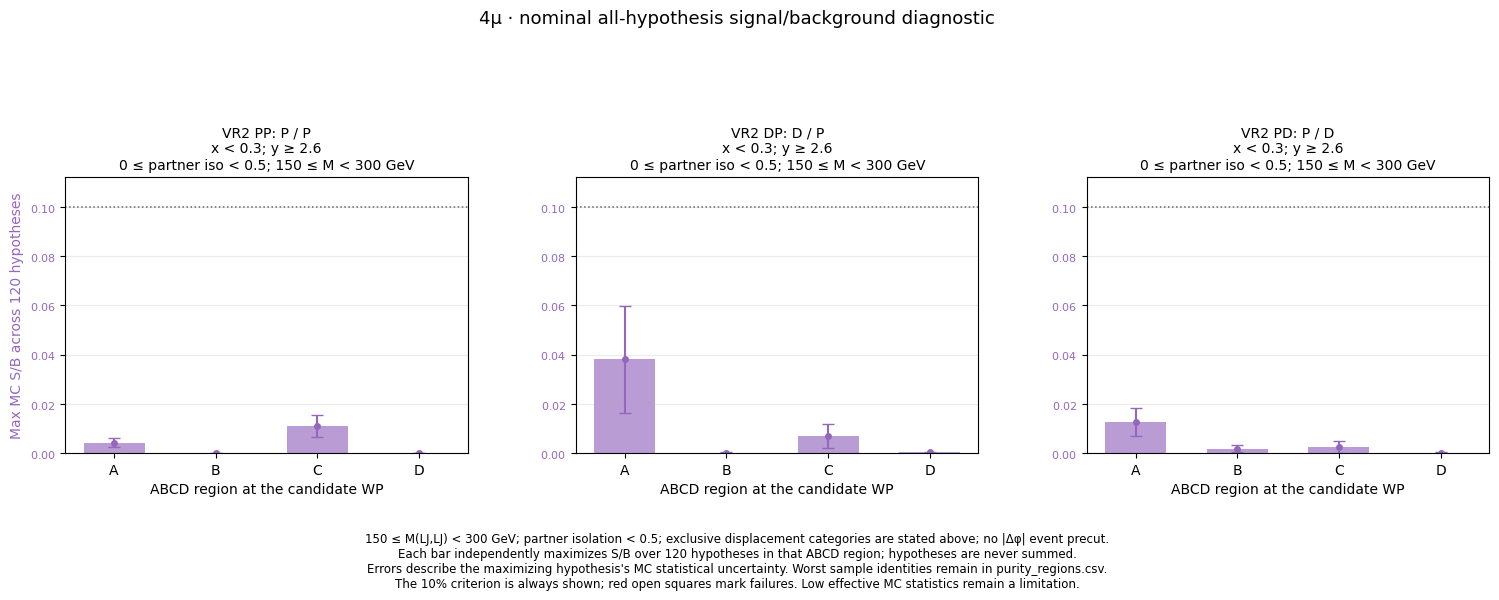

In [6]:
display(figure_lookup['mc_VR_purity_regions'])

### 4.3. DATA Mu iso–Δφ distributions

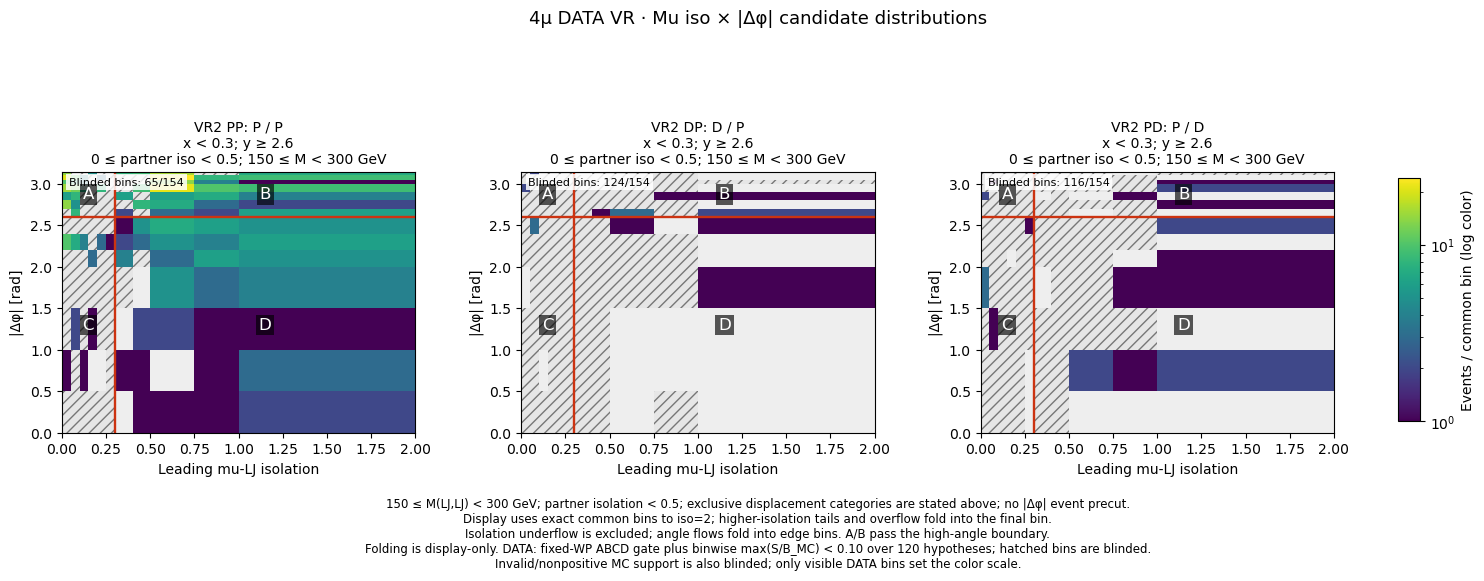

In [7]:
display(figure_lookup['data_VR_planes'])

### 4.4. DATA A, BC/D and κ at the fixed WP

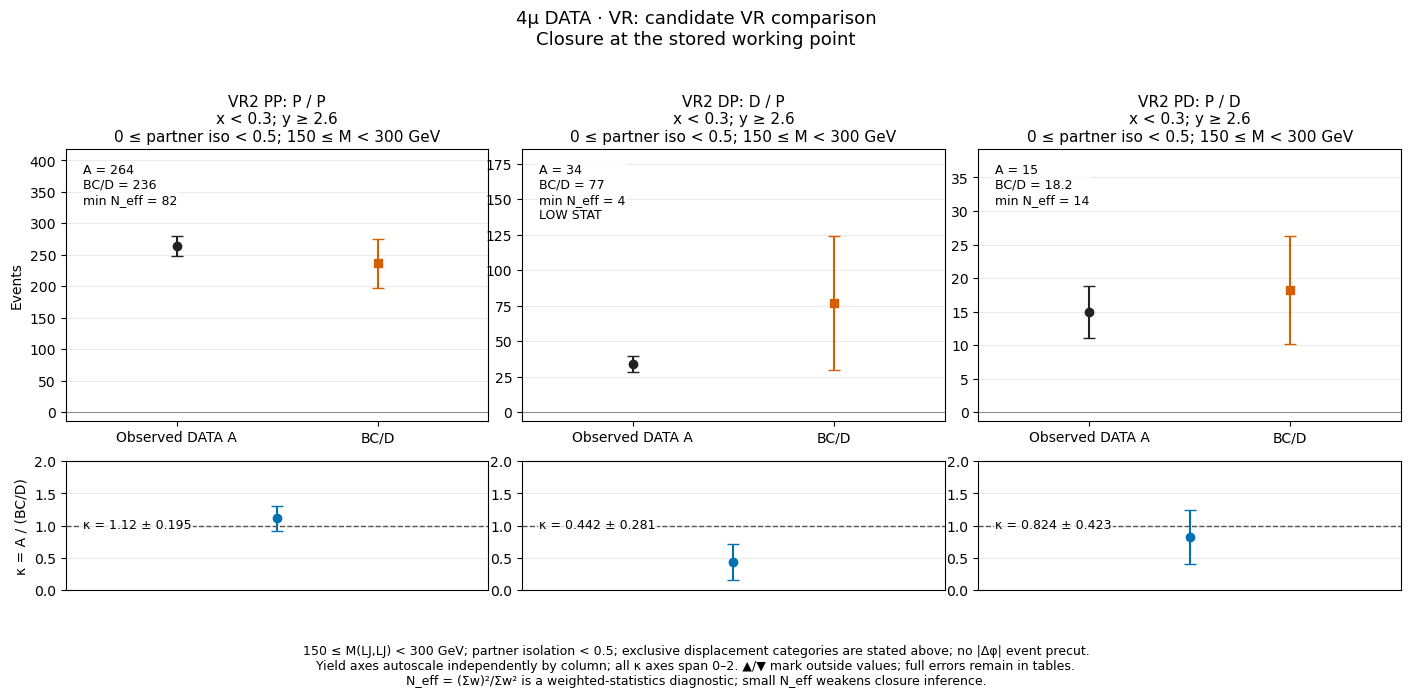

In [8]:
display(figure_lookup['data_VR_selected_closure'])

### 4.5. DATA mu isolation threshold scan

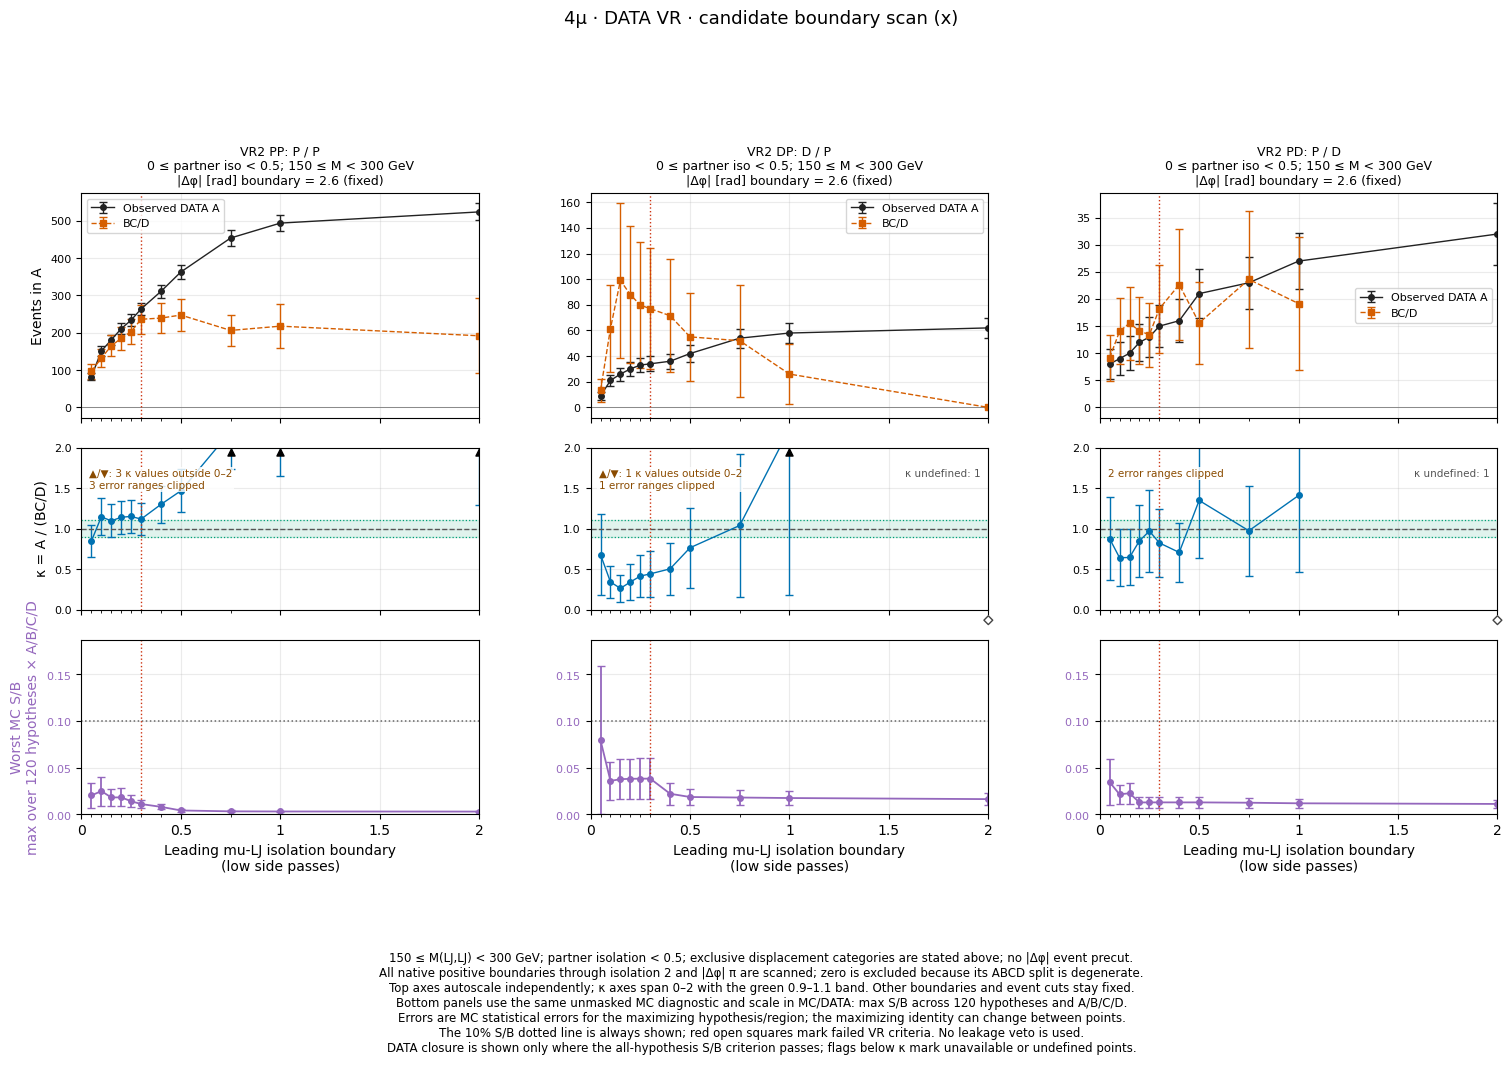

In [9]:
display(figure_lookup['data_VR_x_scan'])

### 4.6. DATA Δφ threshold scan

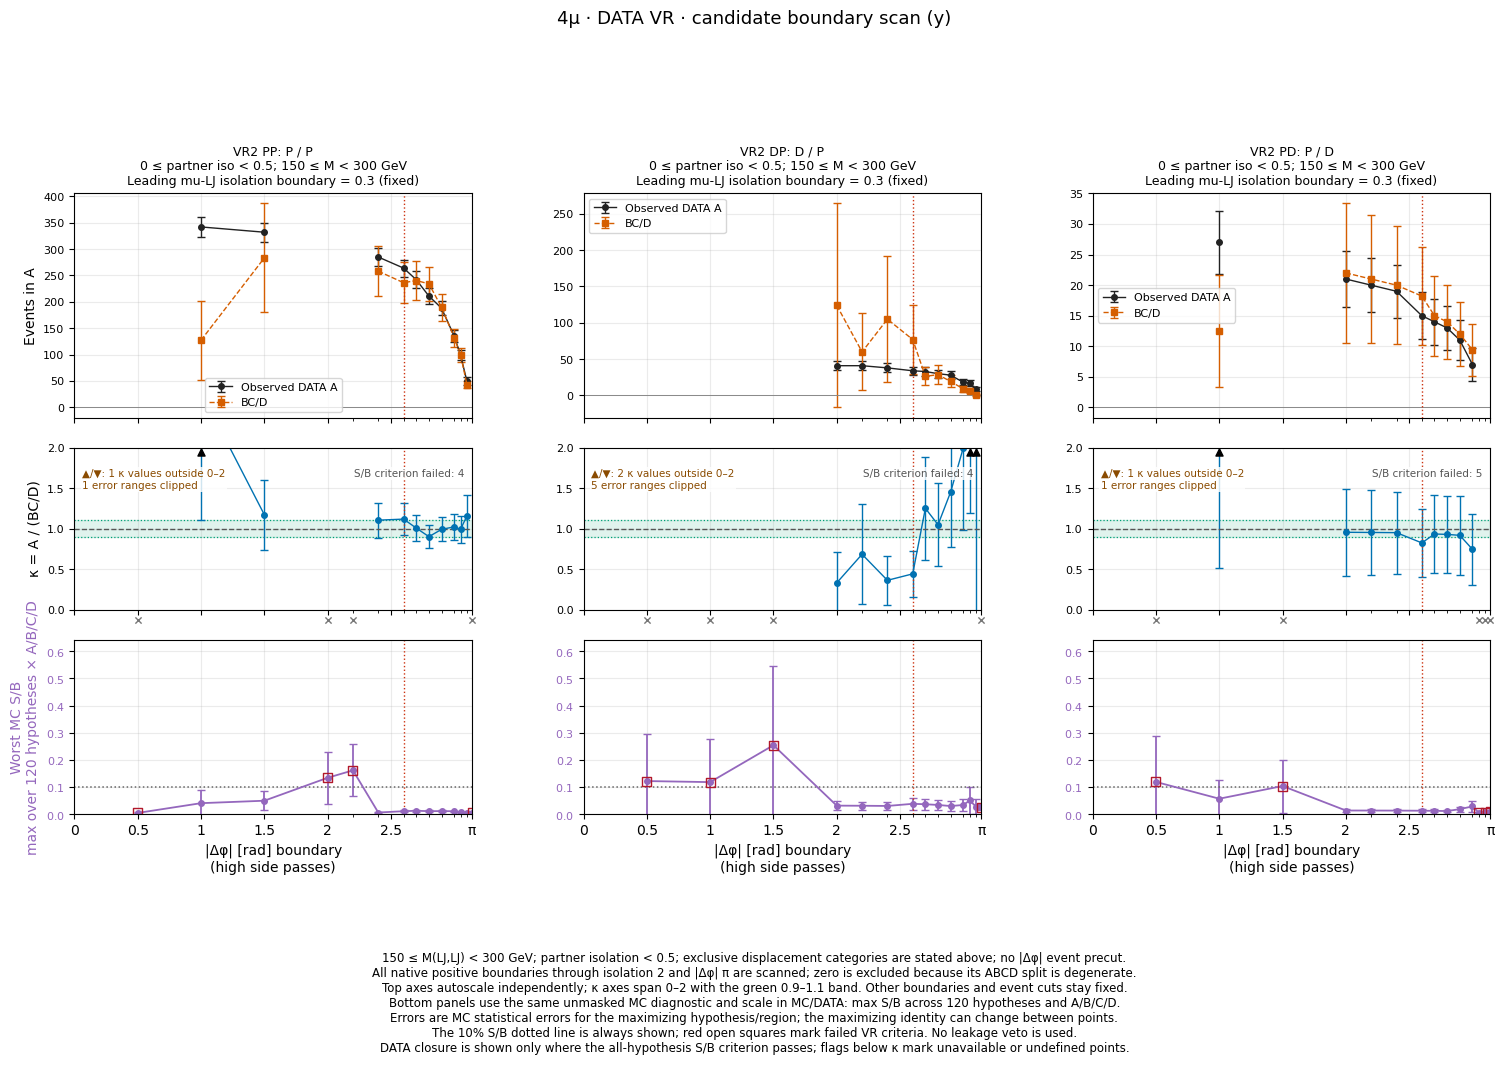

In [10]:
display(figure_lookup['data_VR_y_scan'])

### 4.7. DATA 154-point κ maps

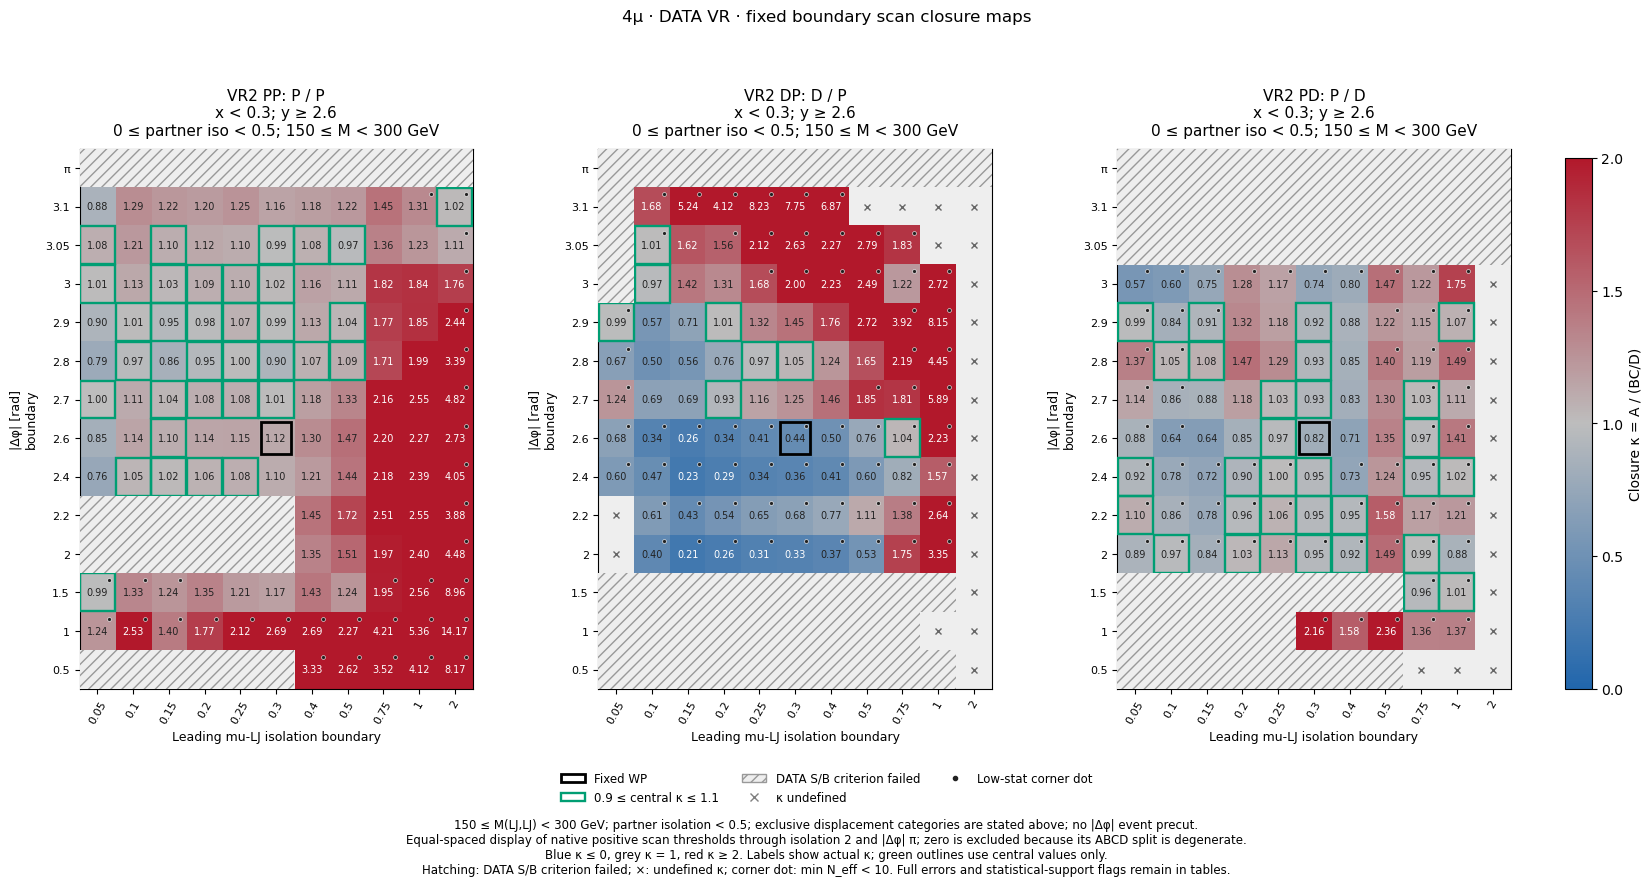

In [11]:
display(figure_lookup['data_VR_closure_grid'])

### 4.8. MC Mu iso–Δφ distributions

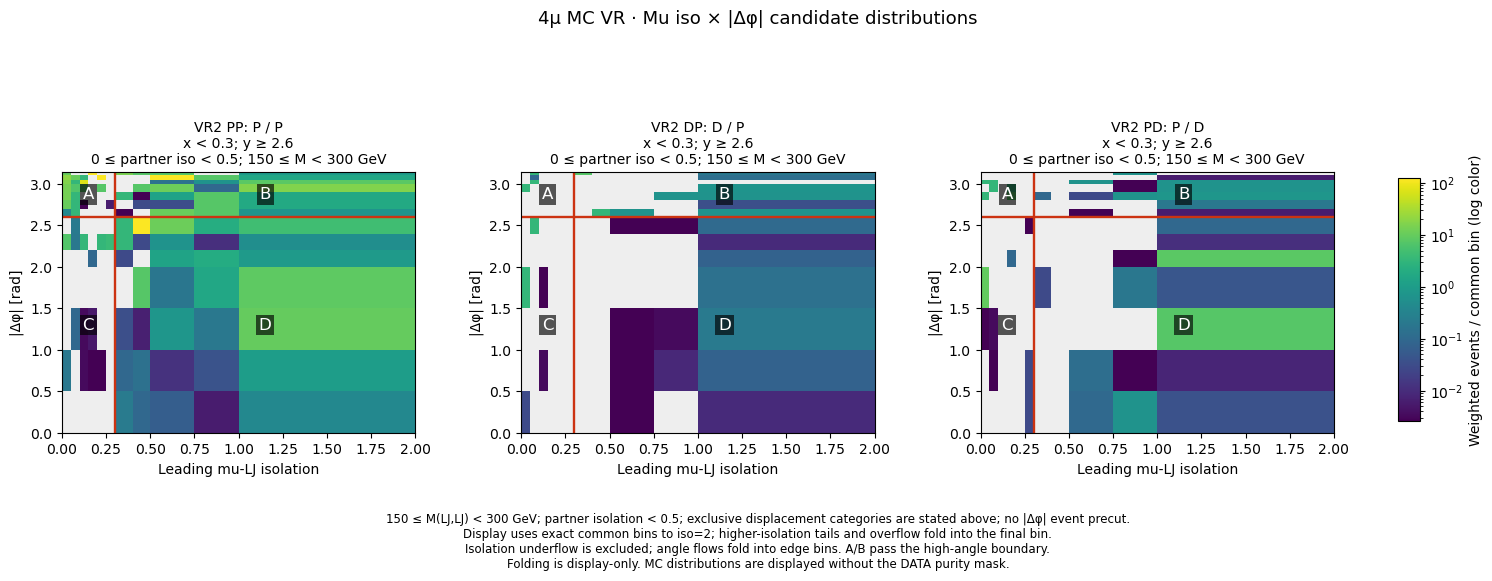

In [12]:
display(figure_lookup['mc_VR_planes'])

### 4.9. MC A, BC/D and κ at the fixed WP

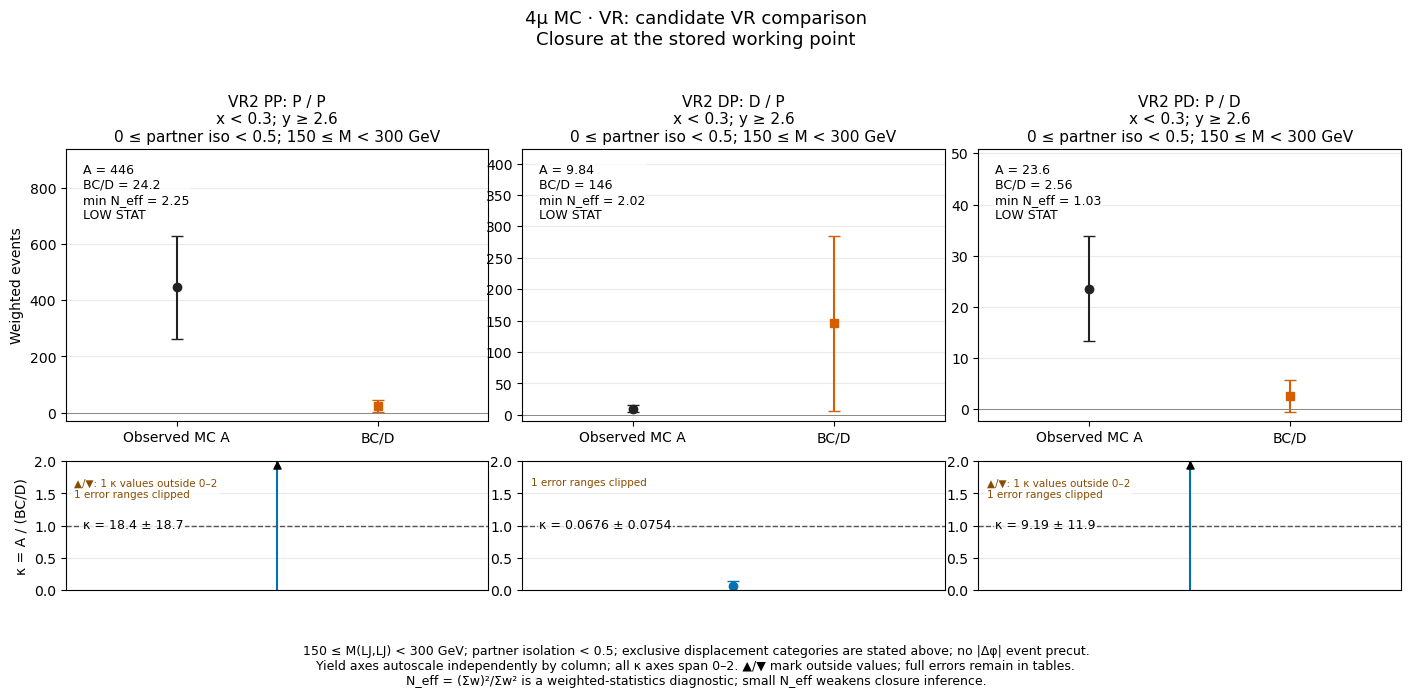

In [13]:
display(figure_lookup['mc_VR_selected_closure'])

### 4.10. MC mu isolation threshold scan

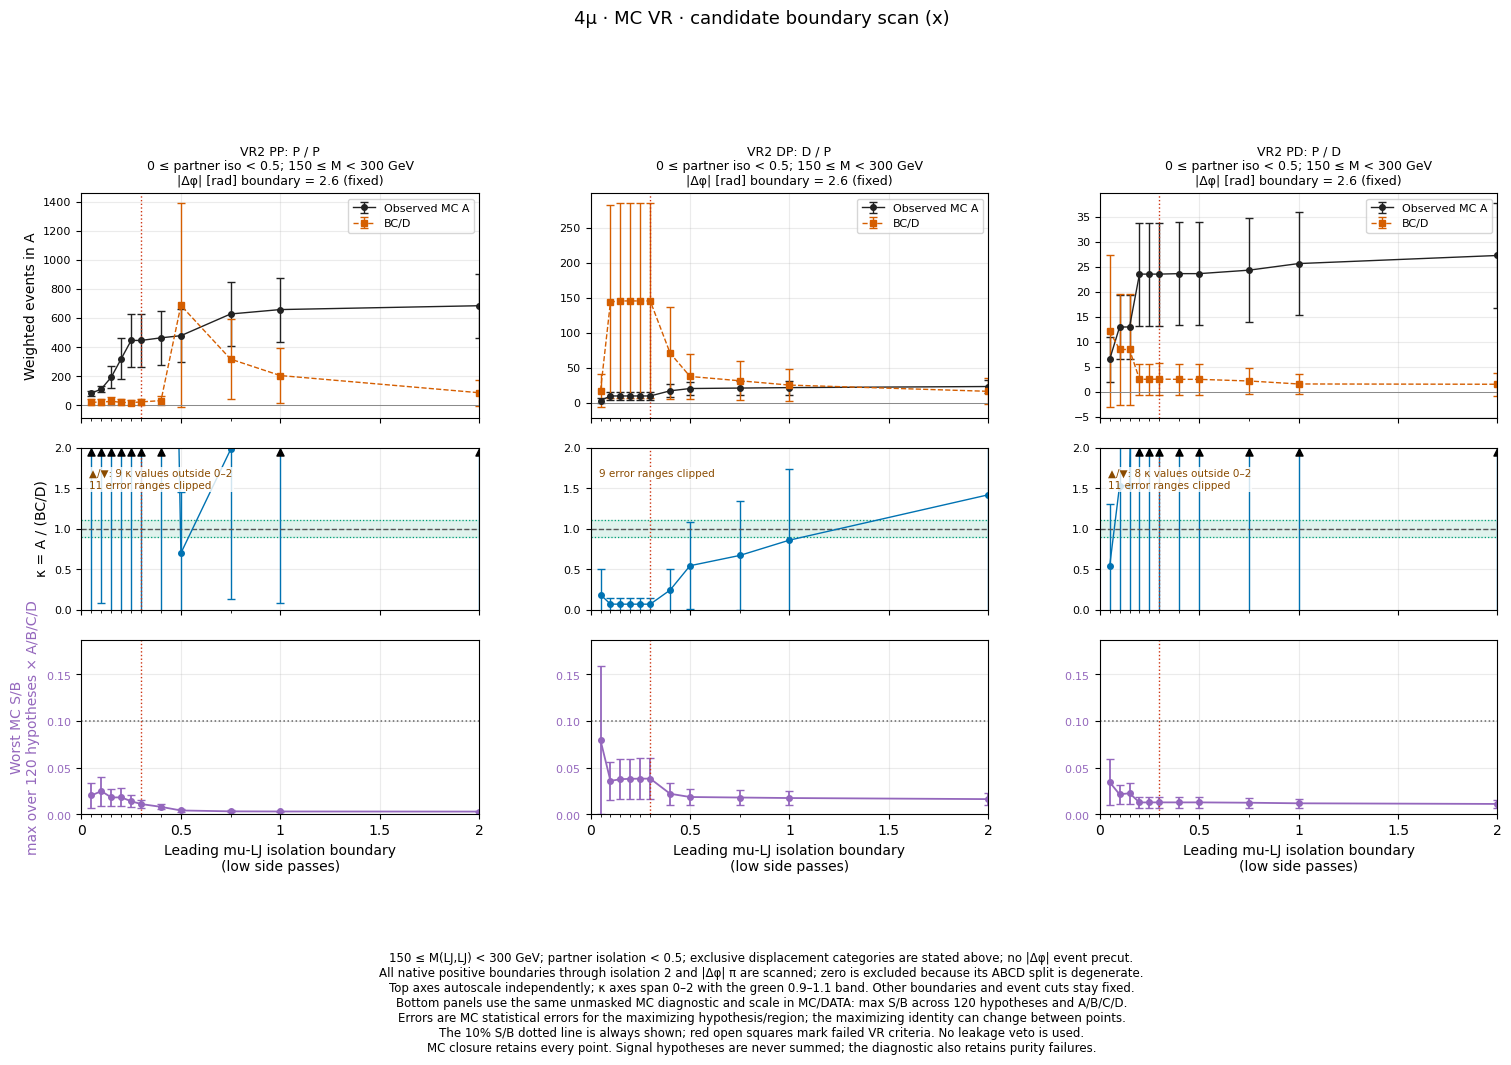

In [14]:
display(figure_lookup['mc_VR_x_scan'])

### 4.11. MC Δφ threshold scan

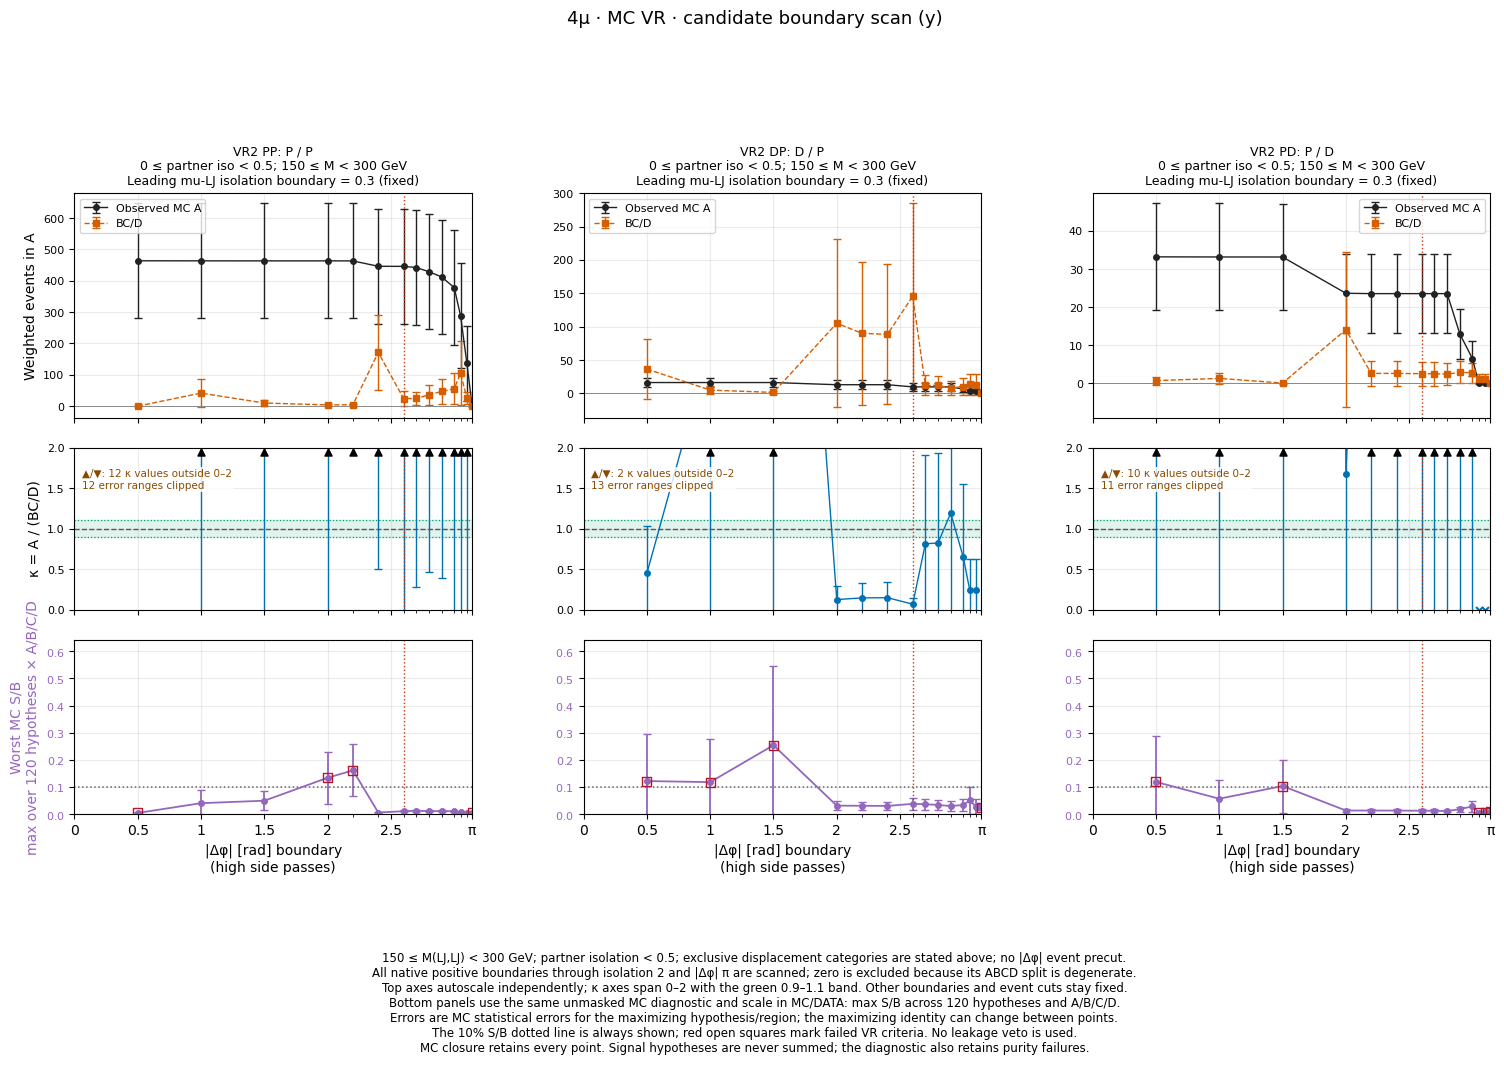

In [15]:
display(figure_lookup['mc_VR_y_scan'])

### 4.12. MC 154-point κ maps

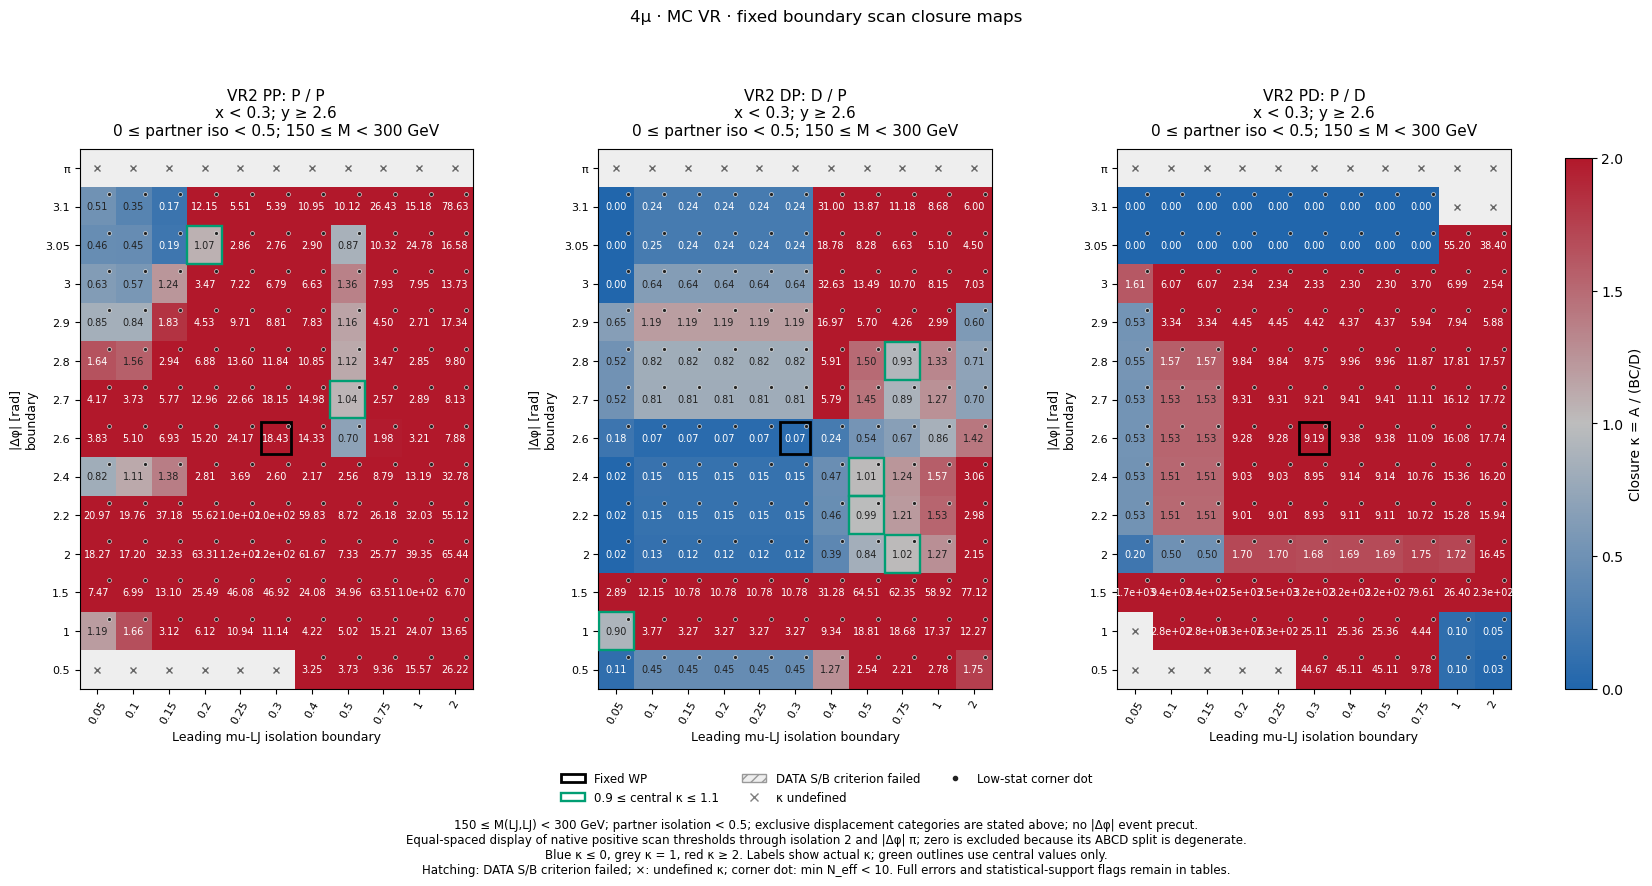

In [16]:
display(figure_lookup['mc_VR_closure_grid'])

### 4.13. MC process composition

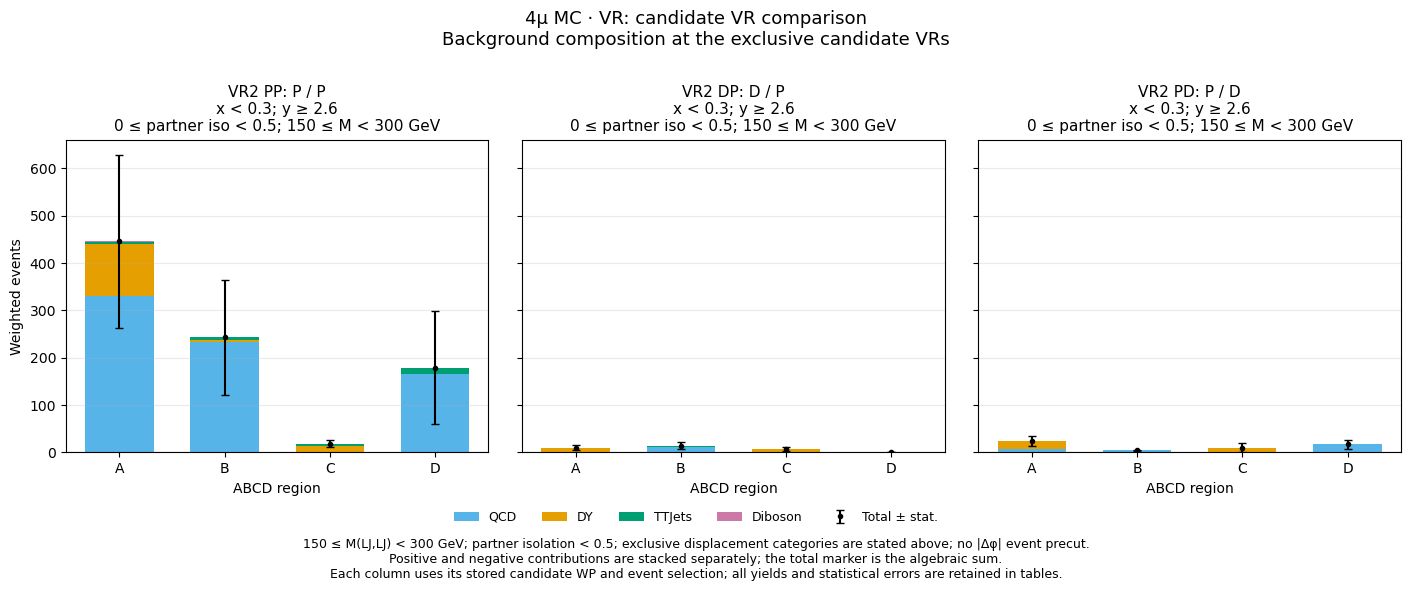

In [17]:
display(figure_lookup['mc_VR_composition'])

### 4.14. MC effective counts in the ABCD regions

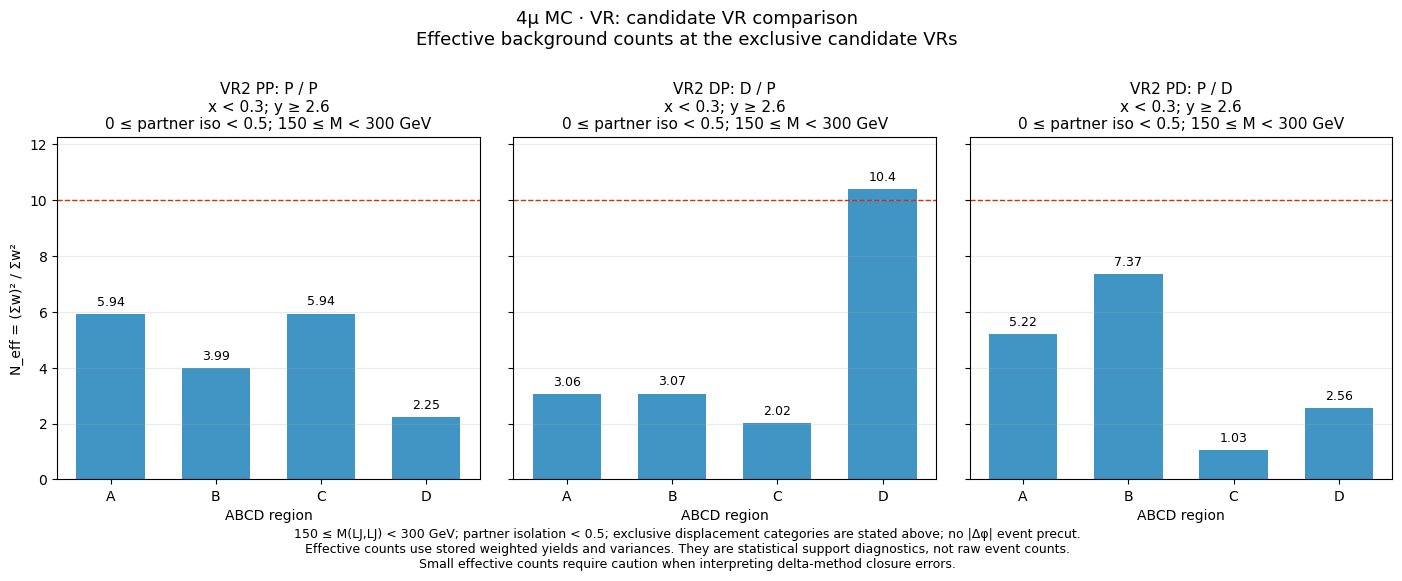

In [18]:
display(figure_lookup['mc_VR_effective_counts'])

### 4.15. DATA All/A/B/C/D correlations and statistics

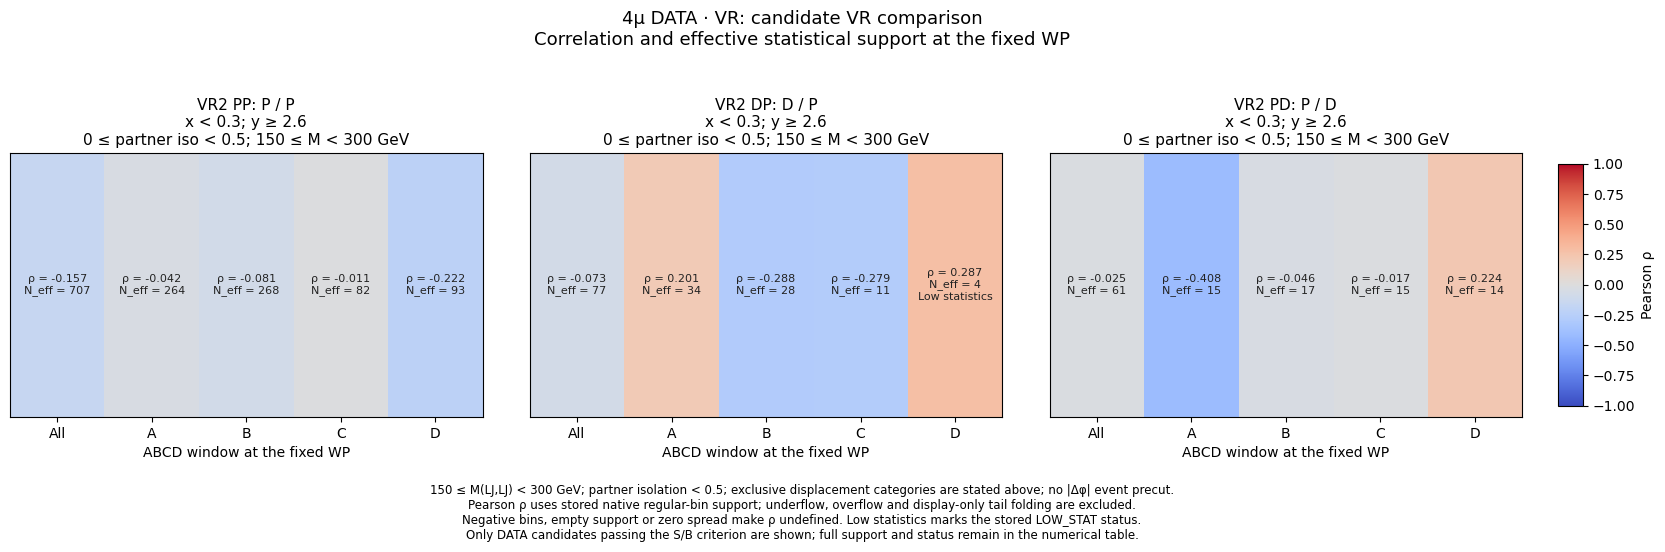

In [19]:
display(figure_lookup['data_VR_correlations'])

### 4.16. MC All/A/B/C/D correlations and statistics

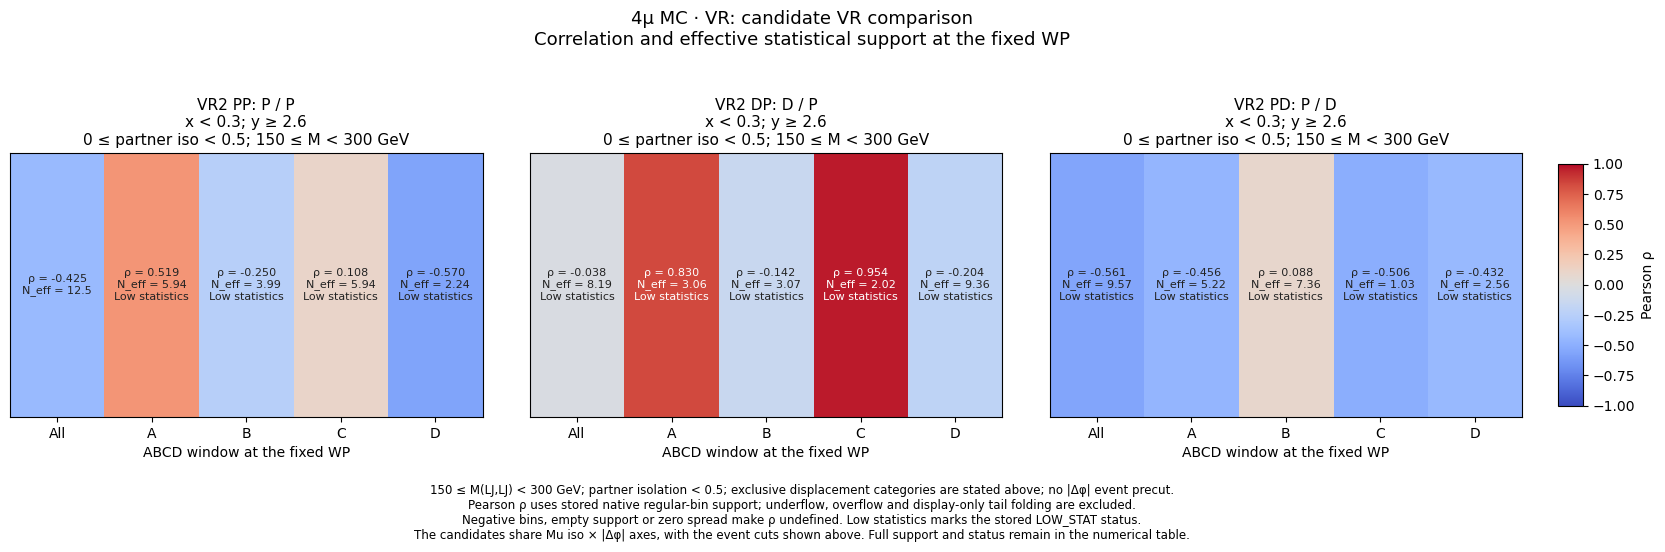

In [20]:
display(figure_lookup['mc_VR_correlations'])

## 5. Nominal MC SR reference

Use the common **DD, Mjj≥150 GeV, 0≤partner iso<0.5** reference from notebooks 11·12.
The fixed WP is **(mu iso, Δφ)=(0.30, 2.6)**, matching the VR. The SR mass and displacement selections are fixed independently.
No additional Δφ event precut is applied. **SR DATA is neither evaluated nor displayed.**

Show the MC SR distribution, fixed-WP closure and 1D/2D scans on the same 154-point grid.
S/B=10% is a reference line and does not mask the MC SR. Cross-check the common-WP values against notebooks 11·12.
Coordinates with iso≤1 are compared with the nominal MC SR tables from notebooks 11·12 and 15·16.
Independently validate the native-bin ABCD sumw, sumw² and total partition sums at all 154 points.
The iso=2 boundary, absent from the earlier tables, is identified in `sr_reference_partition_validation`.
Display this reference in one column because the same SR is compared with every VR category.

In [21]:
with pd.option_context('display.max_columns', None):
    display(tables['sr_reference_selection'])
    display(tables['sr_reference_closure'][['plane', 'source', 'context', 'tx', 'ty', 'A', 'B', 'C', 'D',
                                          'pred', 'pred_error', 'kappa', 'kappa_error', 'neff_min', 'status']])
    display(tables['sr_reference_regression'])

    display(tables['sr_reference_partition_validation'])

,plane,state0,state1,partner_iso_low,partner_iso_high,mass_low,mass_high,tx,ty,scan_mu_iso,scan_abs_dphi,plateau_mu_iso,plateau_abs_dphi,kind,label,selection,x_label,y_label
0,SR,D,D,0.0,0.5,150.0,None,0.3,2.6,"[0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0....","[0.5, 1.0, 1.5, 2.0, 2.2, 2.4, 2.6, 2.7, 2.8, ...",[],[],mu_dphi,Nominal MC SR: D / D,0 ≤ partner iso < 0.5; M ≥ 150 GeV,Leading mu-LJ isolation,|Δφ| [rad]


,plane,source,context,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,status
76,SR,MC,SR,0.3,2.6,3.253182,0.72817,0.002571,0.892088,0.002099,0.003244,1550.183866,2852.868948,1.0,LOW_STAT_SIDEBAND


,table,tx,ty,metric,recalculated,cached,reference_path,passed
0,closure,0.3,2.600000,A,3.253182,3.253182,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True
1,closure,0.3,2.600000,var_A,10.549774,10.549774,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True
2,closure,0.3,2.600000,neff_A,1.003167,1.003167,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True
3,closure,0.3,2.600000,B,0.728170,0.728170,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True
4,closure,0.3,2.600000,var_B,0.435655,0.435655,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True
...,...,...,...,...,...,...,...,...
2800,grid,1.0,3.141593,pred,0.000000,0.000000,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True
2801,grid,1.0,3.141593,pred_error,0.000000,0.000000,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True
2802,grid,1.0,3.141593,kappa,NaN,NaN,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True
2803,grid,1.0,3.141593,kappa_error,NaN,NaN,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/st...,True


,tx,ty,cached_reference_available,check,passed
0,0.05,0.500000,True,Native-bin ABCD sumw/sumw2 and full-plane part...,True
1,0.05,1.000000,True,Native-bin ABCD sumw/sumw2 and full-plane part...,True
2,0.05,1.500000,True,Native-bin ABCD sumw/sumw2 and full-plane part...,True
3,0.05,2.000000,True,Native-bin ABCD sumw/sumw2 and full-plane part...,True
4,0.05,2.200000,True,Native-bin ABCD sumw/sumw2 and full-plane part...,True
...,...,...,...,...,...
149,2.00,2.900000,False,Native-bin ABCD sumw/sumw2 and full-plane part...,True
150,2.00,3.000000,False,Native-bin ABCD sumw/sumw2 and full-plane part...,True
151,2.00,3.050000,False,Native-bin ABCD sumw/sumw2 and full-plane part...,True
152,2.00,3.100000,False,Native-bin ABCD sumw/sumw2 and full-plane part...,True


### 5.1. MC SR Mu iso–Δφ distribution

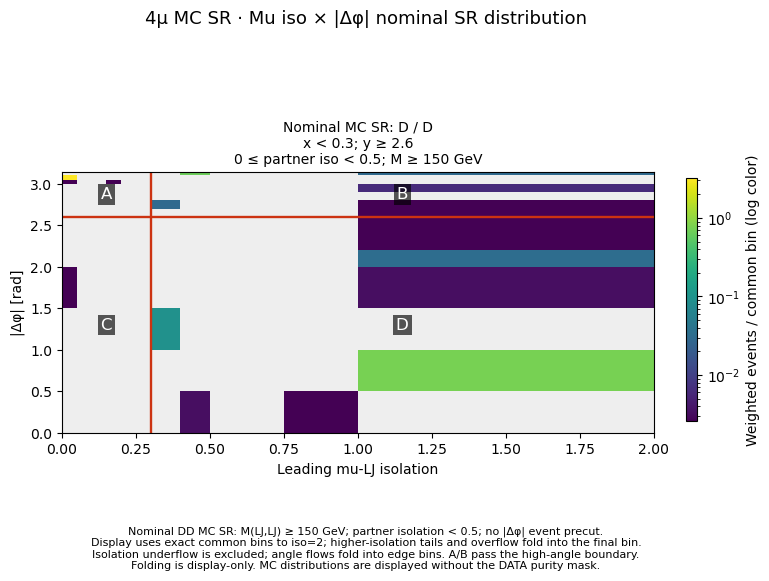

In [22]:
display(figure_lookup['mc_SR_planes'])

### 5.2. MC SR A, BC/D and κ at the fixed WP

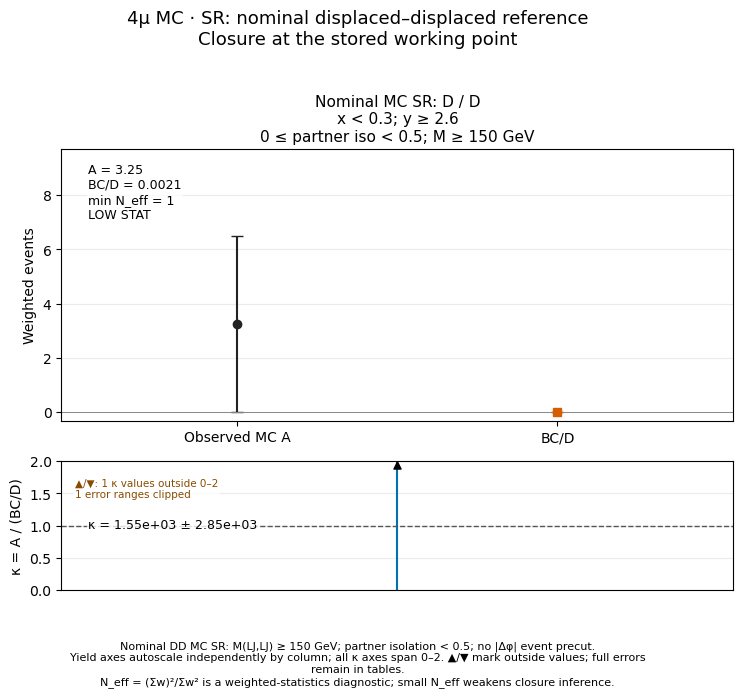

In [23]:
display(figure_lookup['mc_SR_selected_closure'])

### 5.3. MC SR mu isolation threshold scan

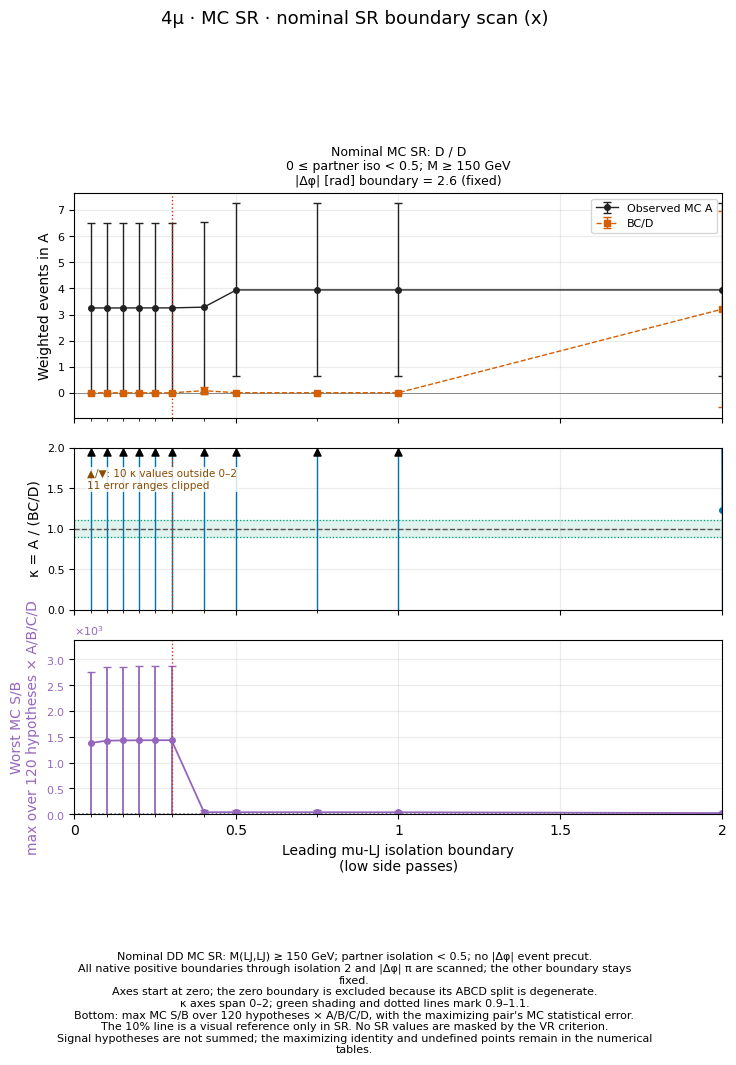

In [24]:
display(figure_lookup['mc_SR_x_scan'])

### 5.4. MC SR Δφ threshold scan

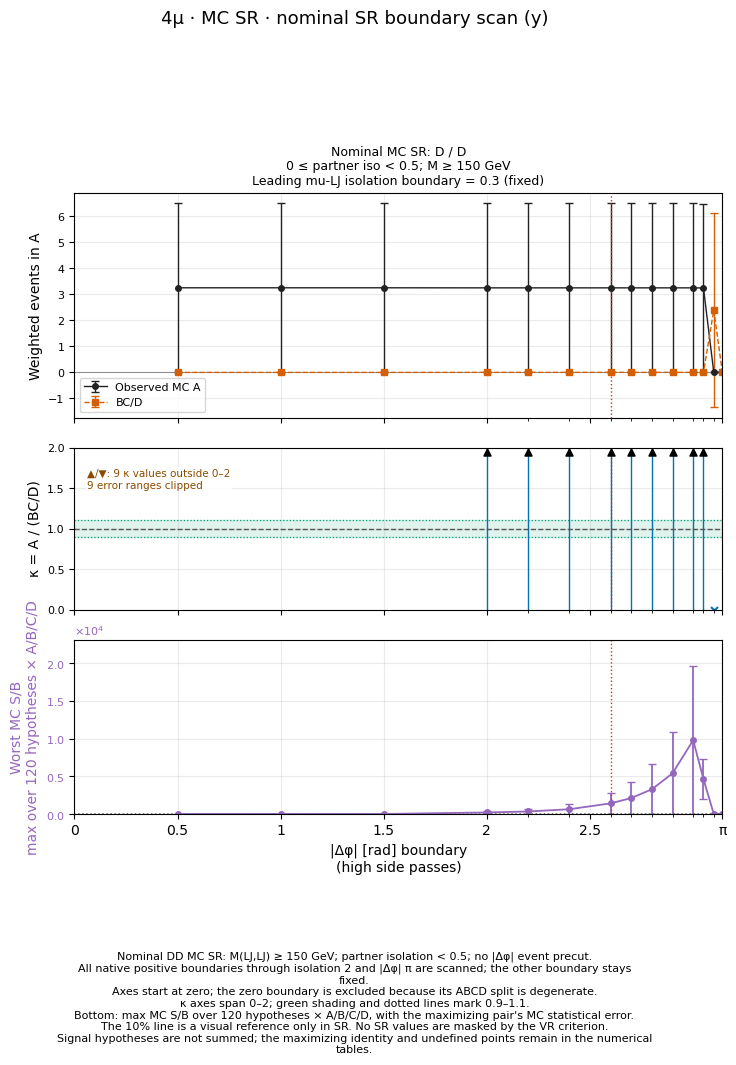

In [25]:
display(figure_lookup['mc_SR_y_scan'])

### 5.5. MC SR 154-point κ map

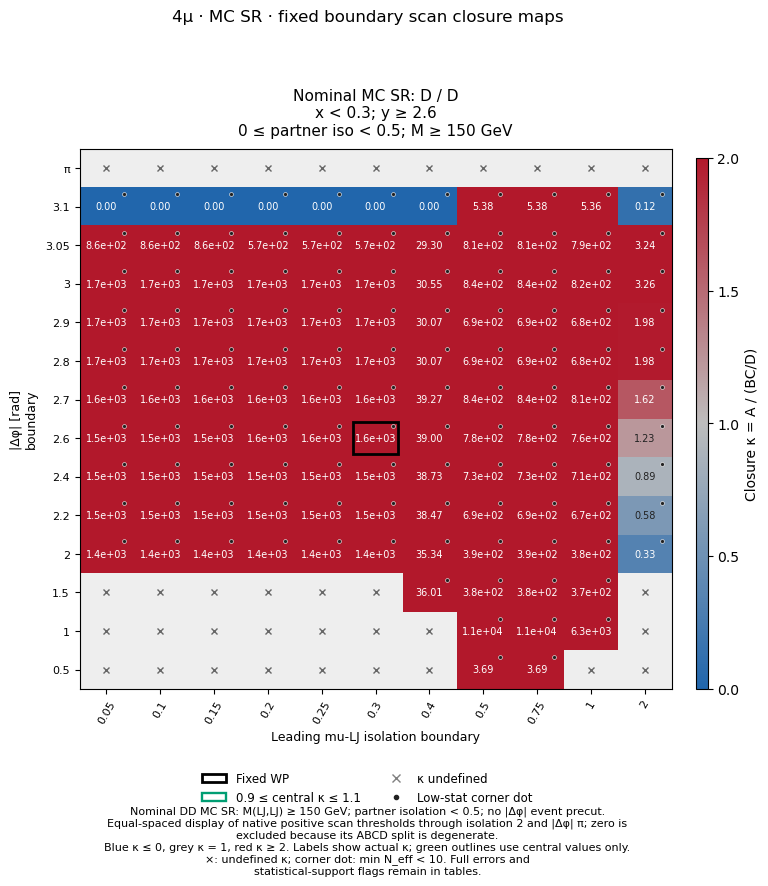

In [26]:
display(figure_lookup['mc_SR_closure_grid'])

## 6. Full signal and scan tables and exports

`purity_regions` contains the maximum S/B, MC statistical uncertainty and signal hypothesis giving the largest S/B in each ABCD region at the fixed WP.
`signal_points.csv` stores ABCD yields, sumw² and S/B for each displacement category, 154 WPs and 120 signal hypotheses.
`sr_reference_*.csv` records the separate nominal MC SR selections, closure, scans, grid, signal diagnostics, regression checks and native-bin partition validation.

Export PNG/PDF figures, the full slide PDF, MC/DATA summaries, scans, composition, correlations, definition checks and input manifests
to this notebook's dedicated outputs directory. Existing `ABCD_plane_summary` results serve as references.
`distribution_bin_purity.csv` stores the MC background, maximum S/B, signal hypothesis giving the largest S/B and mask reason for each displayed bin.
Counts in masked DATA bins are not recorded in this table.


In [27]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', 80):
    display(tables['purity_regions'])
    display(tables['grid'].loc[tables['grid'].source.eq('DATA'),
                              ['plane', 'tx', 'ty', 'kappa', 'kappa_error', 'max_S_B',
                               'approved', 'neff_min', 'status']])
export_candidate_comparison(results, CONFIG, figures)
display(tables['figure_manifest'])
display(Markdown(f'[Full summary slide PDF]({OUTPUT_DIR.name}/comparison_slides.pdf)'))


,plane,context,tx,ty,region,max_S_B,max_S_B_error,worst_sample,approved
0,PP,VR,0.3,2.6,A,0.004244,0.001742,4Mu_200GeV_0p25GeV_0p01mm,True
1,PP,VR,0.3,2.6,B,0.000066,0.000033,4Mu_200GeV_1p2GeV_0p048mm,True
2,PP,VR,0.3,2.6,C,0.010863,0.004458,4Mu_200GeV_0p25GeV_0p01mm,True
3,PP,VR,0.3,2.6,D,0.000019,0.000022,2Mu2E_800GeV_0p25GeV_0p25mm,True
4,DP,VR,0.3,2.6,A,0.038127,0.021808,4Mu_200GeV_0p25GeV_0p1mm,True
5,DP,VR,0.3,2.6,B,0.000207,0.000238,4Mu_800GeV_1p2GeV_0p12mm,True
6,DP,VR,0.3,2.6,C,0.007058,0.004966,4Mu_200GeV_0p25GeV_0p1mm,True
7,DP,VR,0.3,2.6,D,0.000407,0.000181,4Mu_200GeV_1p2GeV_0p48mm,True
8,PD,VR,0.3,2.6,A,0.012649,0.005538,4Mu_200GeV_0p25GeV_0p1mm,True
9,PD,VR,0.3,2.6,B,0.001875,0.001495,4Mu_800GeV_1p2GeV_1p2mm,True


,plane,tx,ty,kappa,kappa_error,max_S_B,approved,neff_min,status
154,PP,0.05,0.500000,NaN,NaN,0.015282,False,NaN,GATE_BLOCKED
155,PP,0.05,1.000000,1.241824,0.951965,0.042232,True,2.0,LOW_STAT_SIDEBAND
156,PP,0.05,1.500000,0.988732,0.493853,0.056972,True,5.0,LOW_STAT_SIDEBAND
157,PP,0.05,2.000000,NaN,NaN,0.153223,False,NaN,GATE_BLOCKED
158,PP,0.05,2.200000,NaN,NaN,0.239919,False,NaN,GATE_BLOCKED
...,...,...,...,...,...,...,...,...,...
919,PD,2.00,2.900000,NaN,NaN,0.016103,True,NaN,NONPOSITIVE_D_OR_NONFINITE_SIDEBAND
920,PD,2.00,3.000000,NaN,NaN,0.023842,True,NaN,NONPOSITIVE_D_OR_NONFINITE_SIDEBAND
921,PD,2.00,3.050000,NaN,NaN,0.214279,False,NaN,GATE_BLOCKED
922,PD,2.00,3.100000,NaN,NaN,0.116130,False,NaN,GATE_BLOCKED


Saved: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_finalize/04_4mu_VR2_summary_outputs


,figure,png,pdf
0,mc_VR_planes,mc_VR_planes.png,mc_VR_planes.pdf
1,data_VR_planes,data_VR_planes.png,data_VR_planes.pdf
2,mc_VR_selected_closure,mc_VR_selected_closure.png,mc_VR_selected_closure.pdf
3,data_VR_selected_closure,data_VR_selected_closure.png,data_VR_selected_closure.pdf
4,mc_VR_x_scan,mc_VR_x_scan.png,mc_VR_x_scan.pdf
5,mc_VR_y_scan,mc_VR_y_scan.png,mc_VR_y_scan.pdf
6,data_VR_x_scan,data_VR_x_scan.png,data_VR_x_scan.pdf
7,data_VR_y_scan,data_VR_y_scan.png,data_VR_y_scan.pdf
8,mc_VR_closure_grid,mc_VR_closure_grid.png,mc_VR_closure_grid.pdf
9,data_VR_closure_grid,data_VR_closure_grid.png,data_VR_closure_grid.pdf


[Full summary slide PDF](04_4mu_VR2_summary_outputs/comparison_slides.pdf)

## Interpretation and limitations

The **PP · DP · PD displacement categories are mutually exclusive** and use a fixed LJ order.
The two channels share the boundaries and partner-isolation requirement, while background composition, statistics and closure are evaluated separately for each category.

Good DATA closure does not guarantee good MC closure. Failed S/B requirements, low MC statistics and uncertainties remain visible.
Do not combine κ values from different categories or scan points as independent measurements.
VR1 is separated from the nominal DD SR by its low mass, and VR2 by its intermediate mass and P requirements.
This notebook diagnoses predefined VRs; it does not optimize a new WP or make a final decision on VR suitability.